<a href="https://colab.research.google.com/github/KRISHNA-EP18/Machine_Learning_IMLE/blob/main/ann.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Importing Libraries

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

In [ ]:
print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [ ]:
x = torch.tensor([[1, 2], [3, 4],[5,6]])

In [ ]:
x*2

tensor([[ 2,  4],
        [ 6,  8],
        [10, 12]])

In [ ]:
x.shape

torch.Size([3, 2])

In [ ]:
k=torch.tensor([1,2])

In [ ]:
k.shape

torch.Size([2])

In [ ]:
x

tensor([[1, 2],
        [3, 4],
        [5, 6]])

In [ ]:
x*k

tensor([[ 1,  4],
        [ 3,  8],
        [ 5, 12]])

In [ ]:
transform = transforms.ToTensor()

In [ ]:
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 56.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.79MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 13.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.21MB/s]


In [ ]:
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [ ]:
print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

Training samples: 60000
Test samples: 10000


In [ ]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([1, 28, 28])
Label: 5


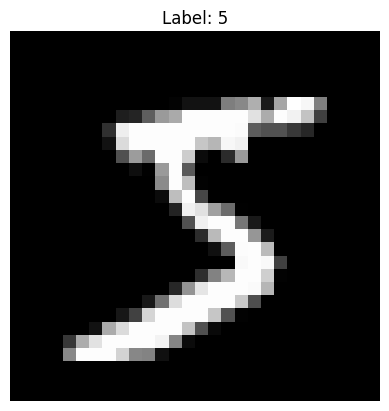

In [ ]:
plt.imshow(image.squeeze(), cmap="gray") #squeeze removes 1 dimension
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

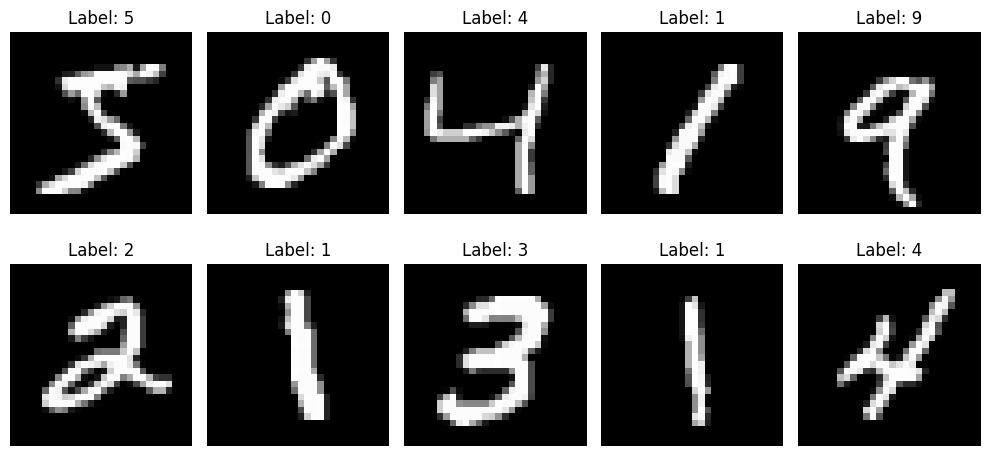

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):

    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
batch_size = 64

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

In [ ]:
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [ ]:
images, labels = next(iter(train_loader))

In [ ]:
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])


In [ ]:
print(labels)

tensor([6, 7, 0, 4, 7, 8, 4, 1, 4, 9, 8, 6, 0, 6, 1, 7, 7, 4, 2, 4, 1, 0, 2, 1,
        3, 8, 5, 2, 1, 3, 1, 4, 6, 6, 4, 2, 7, 1, 7, 7, 0, 8, 7, 8, 9, 4, 0, 8,
        5, 3, 0, 7, 0, 2, 9, 7, 2, 0, 4, 6, 3, 0, 9, 9])


In [ ]:
class ANN(nn.Module):

    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten() #784

        self.network = nn.Sequential(

            nn.Linear(28 * 28, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):

        x = self.flatten(x)

        x = self.network(x)

        return x

In [ ]:
model = ANN()

model = model.to(device)

print(model)

ANN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
total_parameters = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_parameters)

Total parameters: 109386


In [ ]:
for name, parameter in model.named_parameters():

    print(
        name,
        parameter.shape,
        parameter.numel()
    )

network.0.weight torch.Size([128, 784]) 100352
network.0.bias torch.Size([128]) 128
network.2.weight torch.Size([64, 128]) 8192
network.2.bias torch.Size([64]) 64
network.4.weight torch.Size([10, 64]) 640
network.4.bias torch.Size([10]) 10


In [ ]:
images = images.to(device)
labels = labels.to(device)

In [ ]:
outputs = model(images)

In [ ]:
print(outputs.shape)

torch.Size([64, 10])


In [ ]:
print(outputs[0]) #These are called logits.

tensor([-0.0062, -0.0874, -0.1208, -0.0753,  0.0908,  0.1009,  0.0574, -0.0166,
         0.0917,  0.0941], grad_fn=<SelectBackward0>)


In [ ]:
prediction = torch.argmax(outputs[0])

In [ ]:
print("Prediction:", prediction.item())
print("Actual:", labels[0].item())

Prediction: 5
Actual: 6


In [ ]:
predictions = torch.argmax(outputs, dim=1)

print(predictions)
print(labels)

tensor([5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 9, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 9, 4, 4, 4, 4,
        4, 4, 9, 4, 4, 5, 9, 4, 4, 4, 4, 4, 4, 4, 4, 4])
tensor([6, 7, 0, 4, 7, 8, 4, 1, 4, 9, 8, 6, 0, 6, 1, 7, 7, 4, 2, 4, 1, 0, 2, 1,
        3, 8, 5, 2, 1, 3, 1, 4, 6, 6, 4, 2, 7, 1, 7, 7, 0, 8, 7, 8, 9, 4, 0, 8,
        5, 3, 0, 7, 0, 2, 9, 7, 2, 0, 4, 6, 3, 0, 9, 9])


In [ ]:
criterion = nn.CrossEntropyLoss()

In [ ]:
loss = criterion(outputs, labels)

print("Loss:", loss.item())

Loss: 2.3084354400634766


In [ ]:
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
model.parameters()

<generator object Module.parameters at 0x7fb9b2511460>

In [ ]:
print(model.network[0].weight.grad)

None


In [ ]:
loss.backward()

In [ ]:
print(model.network[0].weight.grad.shape)

torch.Size([128, 784])


In [ ]:
print(model.network[0].weight.grad)

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])


In [ ]:
old_weight = model.network[0].weight[0, 0].item()

print("Before:", old_weight)

Before: 0.00792410597205162


In [ ]:
optimizer.step()

In [ ]:
new_weight = model.network[0].weight[0, 0].item()

print("After:", new_weight)

After: 0.00792410597205162


In [ ]:
optimizer.zero_grad()

In [ ]:
num_epochs = 5

train_losses = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear old gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(images)

        # 3. Calculate loss
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    train_losses.append(average_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/5] Loss: 0.3398
Epoch [2/5] Loss: 0.1383
Epoch [3/5] Loss: 0.0982
Epoch [4/5] Loss: 0.0754
Epoch [5/5] Loss: 0.0613


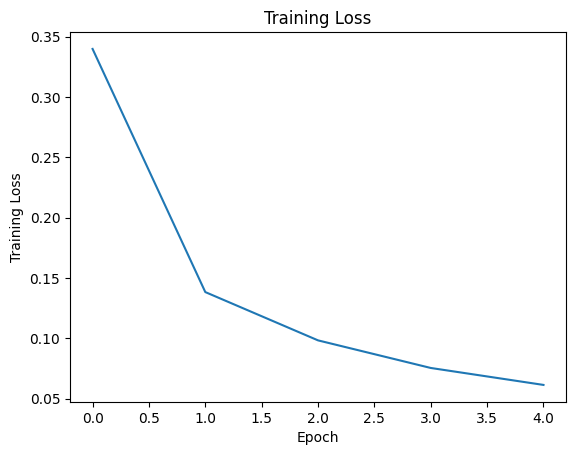

In [ ]:
plt.plot(train_losses)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")

plt.show()

In [ ]:
model.eval()

ANN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [ ]:
correct = 0
total = 0

In [ ]:
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        total += labels.size(0)

        correct += (
            predictions == labels
        ).sum().item()

In [ ]:
accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 97.57%


In [ ]:
all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

In [ ]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)


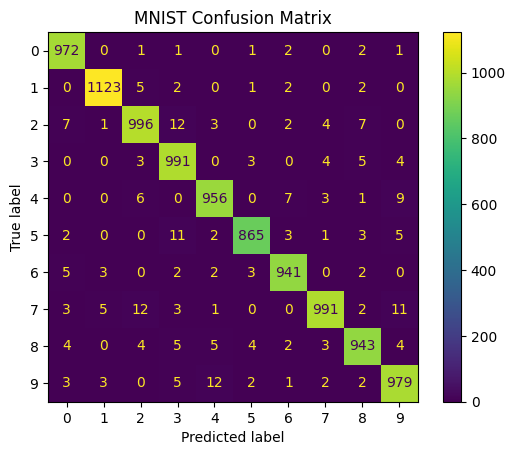

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

disp.plot()

plt.title("MNIST Confusion Matrix")
plt.show()

In [ ]:
print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9759    0.9918    0.9838       980
           1     0.9894    0.9894    0.9894      1135
           2     0.9698    0.9651    0.9675      1032
           3     0.9603    0.9812    0.9706      1010
           4     0.9745    0.9735    0.9740       982
           5     0.9841    0.9697    0.9768       892
           6     0.9802    0.9823    0.9812       958
           7     0.9831    0.9640    0.9735      1028
           8     0.9732    0.9682    0.9707       974
           9     0.9664    0.9703    0.9683      1009

    accuracy                         0.9757     10000
   macro avg     0.9757    0.9756    0.9756     10000
weighted avg     0.9758    0.9757    0.9757     10000



In [ ]:
images, labels = next(iter(test_loader))

images_device = images.to(device)

model.eval()

with torch.no_grad():

    outputs = model(images_device)

    predictions = torch.argmax(
        outputs,
        dim=1
    )

predictions = predictions.cpu()

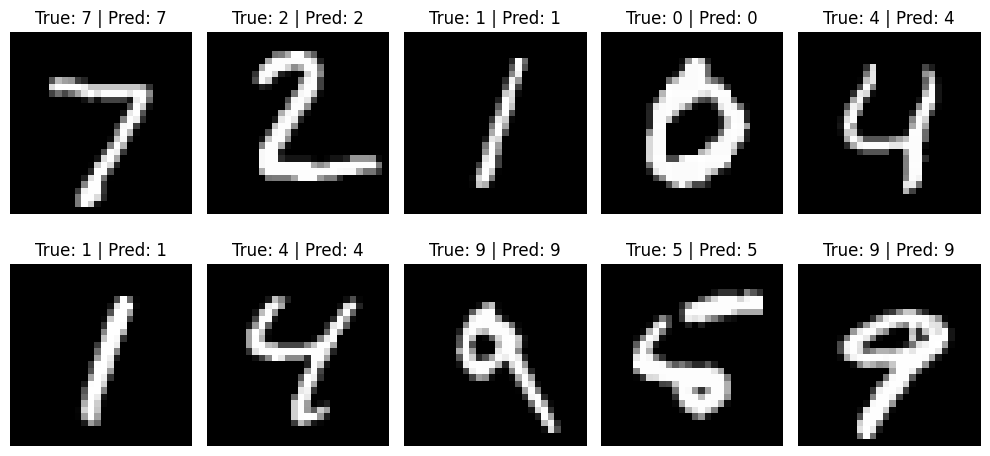

In [ ]:
fig, axes = plt.subplots(
    2, 5,
    figsize=(10, 5)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        images[i].squeeze(),
        cmap="gray"
    )

    ax.set_title(
        f"True: {labels[i].item()} | "
        f"Pred: {predictions[i].item()}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()